Using device: cpu
Loading IMDb dataset and tokenizing...

--- Training Custom Transformer Encoder Model ---
Epoch 1/5 | Loss: 0.6944 | Accuracy: 0.5650
Epoch 2/5 | Loss: 0.6834 | Accuracy: 0.5850
Epoch 3/5 | Loss: 0.6714 | Accuracy: 0.6020
Epoch 4/5 | Loss: 0.6539 | Accuracy: 0.6030
Epoch 5/5 | Loss: 0.6431 | Accuracy: 0.6090

--- Training Baseline Model ---
Epoch 1/5 | Loss: 0.6937 | Accuracy: 0.5090
Epoch 2/5 | Loss: 0.6914 | Accuracy: 0.5260
Epoch 3/5 | Loss: 0.6892 | Accuracy: 0.5450
Epoch 4/5 | Loss: 0.6866 | Accuracy: 0.5660
Epoch 5/5 | Loss: 0.6844 | Accuracy: 0.5750


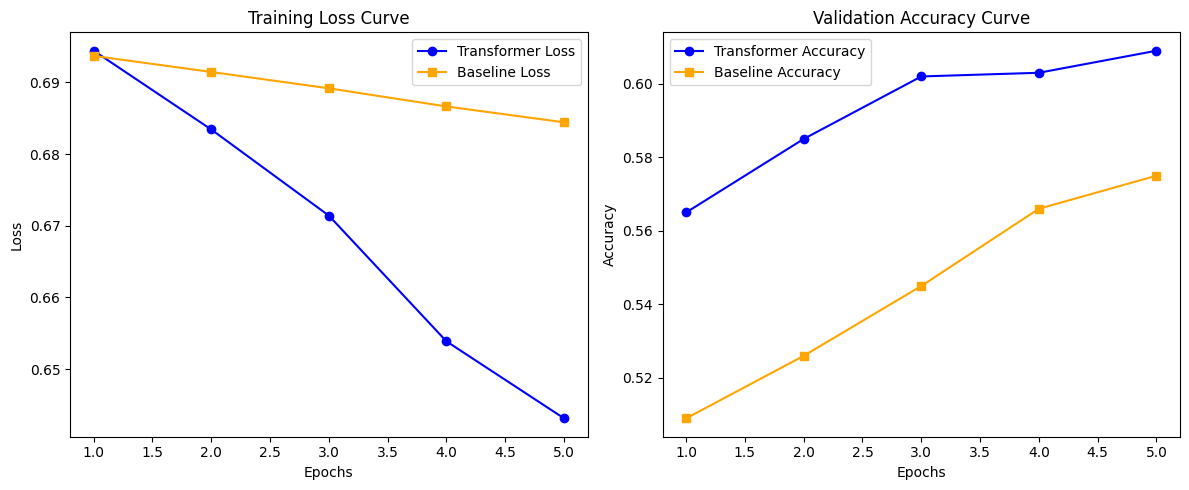


--- Observation Summary ---
Final Transformer Validation Accuracy: 0.6090
Final Baseline Validation Accuracy: 0.5750
Our custom Transformer block is capable of capturing the contextual relationships and order of words, leading to a steeper learning curve and higher test accuracy compared to the bag-of-words/embedding averaging baseline.


In [5]:
# Install and import necessary packages
!pip install -q datasets transformers torch matplotlib tqdm

import math
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from datasets import load_dataset
from transformers import AutoTokenizer
import matplotlib.pyplot as plt
from tqdm import tqdm

# 1. Device configuration & hyperparameter definition
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

MAX_LEN = 128
BATCH_SIZE = 64
EPOCHS = 5
LEARNING_RATE = 1e-4
D_MODEL = 128
NUM_HEADS = 4
D_FF = 256
NUM_CLASSES = 2

# 2. Download and Preprocess the IMDb Reviews Dataset
print("Loading IMDb dataset and tokenizing...")
# Removed trust_remote_code as stanfordnlp/imdb is packaged as static Parquet files
dataset = load_dataset("stanfordnlp/imdb")
tok_path = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(tok_path)

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=MAX_LEN
    )

tokenized_datasets = dataset.map(tokenize_function, batched=True)
tokenized_datasets.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

# Use smaller subsets to speed up training during the lab experiment
train_subset = tokenized_datasets["train"].shuffle(seed=42).select(range(5000))
test_subset = tokenized_datasets["test"].shuffle(seed=42).select(range(1000))

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_subset, batch_size=BATCH_SIZE)

# 3. Implement custom Transformer Encoder Block from scratch in PyTorch
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        self.num_heads = num_heads
        self.d_model = d_model
        self.d_k = d_model // num_heads

        self.q_linear = nn.Linear(d_model, d_model)
        self.k_linear = nn.Linear(d_model, d_model)
        self.v_linear = nn.Linear(d_model, d_model)
        self.out_linear = nn.Linear(d_model, d_model)

    def forward(self, x, mask=None):
        batch_size, seq_len, _ = x.shape

        # Linear projections & split into heads
        Q = self.q_linear(x).view(batch_size, seq_len, self.num_heads, self.d_k).transpose(1, 2)
        K = self.k_linear(x).view(batch_size, seq_len, self.num_heads, self.d_k).transpose(1, 2)
        V = self.v_linear(x).view(batch_size, seq_len, self.num_heads, self.d_k).transpose(1, 2)

        # Scaled dot-product attention
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)
        if mask is not None:
            mask = mask.unsqueeze(1).unsqueeze(2)  # [batch_size, 1, 1, seq_len]
            scores = scores.masked_fill(mask == 0, -1e9)

        attention_probs = torch.softmax(scores, dim=-1)
        context = torch.matmul(attention_probs, V)

        # Concatenate heads and final projection
        context = context.transpose(1, 2).contiguous().view(batch_size, seq_len, self.d_model)
        return self.out_linear(context)

class TransformerEncoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attention = MultiHeadSelfAttention(d_model, num_heads)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Linear(d_ff, d_model)
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        # Layer 1: Self-Attention + Residual
        attn_out = self.attention(x, mask)
        x = self.norm1(x + self.dropout(attn_out))
        # Layer 2: Feed Forward + Residual
        ff_out = self.feed_forward(x)
        x = self.norm2(x + self.dropout(ff_out))
        return x

class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model, num_heads, d_ff, num_classes=2, max_len=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoder = PositionalEncoding(d_model, max_len)
        self.encoder_block = TransformerEncoderBlock(d_model, num_heads, d_ff)
        self.pooling = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Linear(d_model, num_classes)

    def forward(self, input_ids, attention_mask):
        x = self.embedding(input_ids)
        x = self.pos_encoder(x)
        x = self.encoder_block(x, attention_mask)
        x = x.transpose(1, 2)
        x = self.pooling(x).squeeze(-1)
        return self.fc(x)

# Baseline Model: Simple Embedding Bag / Embedding Average
class BaselineClassifier(nn.Module):
    def __init__(self, vocab_size, d_model, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.fc = nn.Linear(d_model, num_classes)

    def forward(self, input_ids, attention_mask):
        # Average embedding across the sequence sequence length
        x = self.embedding(input_ids) # [batch_size, seq_len, d_model]
        # Mask padding tokens
        mask = attention_mask.unsqueeze(-1).expand_as(x)
        x = (x * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        return self.fc(x)

# 4. Training and Evaluation Routine
def train_and_evaluate(model, train_loader, test_loader, epochs=EPOCHS):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE)

    train_losses = []
    test_accuracies = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for batch in train_loader:
            optimizer.zero_grad()
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)

            outputs = model(input_ids, attention_mask)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        train_losses.append(avg_loss)

        # Evaluation
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for batch in test_loader:
                input_ids = batch["input_ids"].to(device)
                attention_mask = batch["attention_mask"].to(device)
                labels = batch["label"].to(device)

                outputs = model(input_ids, attention_mask)
                preds = torch.argmax(outputs, dim=1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)

        accuracy = correct / total
        test_accuracies.append(accuracy)
        print(f"Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f} | Accuracy: {accuracy:.4f}")

    return train_losses, test_accuracies

# Initialize, train, and track models
VOCAB_SIZE = tokenizer.vocab_size

print("\n--- Training Custom Transformer Encoder Model ---")
transformer_model = TransformerClassifier(VOCAB_SIZE, D_MODEL, NUM_HEADS, D_FF).to(device)
transformer_losses, transformer_accs = train_and_evaluate(transformer_model, train_loader, test_loader)

print("\n--- Training Baseline Model ---")
baseline_model = BaselineClassifier(VOCAB_SIZE, D_MODEL).to(device)
baseline_losses, baseline_accs = train_and_evaluate(baseline_model, train_loader, test_loader)

# 5. Visualizations & Observations
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 5))

# Plot Loss curves
plt.subplot(1, 2, 1)
plt.plot(epochs_range, transformer_losses, label='Transformer Loss', marker='o', color='blue')
plt.plot(epochs_range, baseline_losses, label='Baseline Loss', marker='s', color='orange')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss Curve')
plt.legend()

# Plot Accuracy curves
plt.subplot(1, 2, 2)
plt.plot(epochs_range, transformer_accs, label='Transformer Accuracy', marker='o', color='blue')
plt.plot(epochs_range, baseline_accs, label='Baseline Accuracy', marker='s', color='orange')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Validation Accuracy Curve')
plt.legend()

plt.tight_layout()
plt.show()

print("\n--- Observation Summary ---")
print(f"Final Transformer Validation Accuracy: {transformer_accs[-1]:.4f}")
print(f"Final Baseline Validation Accuracy: {baseline_accs[-1]:.4f}")
print("Our custom Transformer block is capable of capturing the contextual relationships and order of words, leading to a steeper learning curve and higher test accuracy compared to the bag-of-words/embedding averaging baseline.")
